In [43]:
import pandas as pd
import matplotlib.pyplot as plt


import seaborn as sns

In [2]:
dataset=pd.read_csv('koi_cumulative.csv')

In [3]:
dataset.head()

,kepid,kepoi_name,kepler_name,koi_disposition,koi_pdisposition,koi_score,koi_fpflag_nt,koi_fpflag_ss,koi_fpflag_co,koi_fpflag_ec,...,koi_steff_err2,koi_slogg,koi_slogg_err1,koi_slogg_err2,koi_srad,koi_srad_err1,koi_srad_err2,ra,dec,koi_kepmag
0,10797460,K00752.01,Kepler-227 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
1,10797460,K00752.02,Kepler-227 c,CONFIRMED,CANDIDATE,0.969,0,0,0,0,...,-81.0,4.467,0.064,-0.096,0.927,0.105,-0.061,291.93423,48.141651,15.347
2,10811496,K00753.01,NaN,CANDIDATE,CANDIDATE,0.000,0,0,0,0,...,-176.0,4.544,0.044,-0.176,0.868,0.233,-0.078,297.00482,48.134129,15.436
3,10848459,K00754.01,NaN,FALSE POSITIVE,FALSE POSITIVE,0.000,0,1,0,0,...,-174.0,4.564,0.053,-0.168,0.791,0.201,-0.067,285.53461,48.285210,15.597
4,10854555,K00755.01,Kepler-664 b,CONFIRMED,CANDIDATE,1.000,0,0,0,0,...,-211.0,4.438,0.070,-0.210,1.046,0.334,-0.133,288.75488,48.226200,15.509


In [6]:
dataset.shape

(9564, 49)

In [7]:
datasets=pd.read_csv('koi_cumulative_metadata.csv')

In [8]:
datasets

,column_name,description,unit,datatype
0,kepid,KIC Identification Number,NaN,int
1,kepoi_name,Kepler Object of Interest Name,NaN,char
2,kepler_name,Kepler Name (confirmed planet),NaN,char
3,ra,RA Value [decimal degrees],degrees,double
4,ra_err,RA Uncertainty [decimal degrees],degrees,double
...,...,...,...,...
148,koi_srho,Fitted Stellar Density Value [g/cm*3],NaN,double
149,koi_srho_err1,Fitted Stellar Density Upper Uncertainty [g/cm*3],NaN,double
150,koi_srho_err2,Fitted Stellar Density Lower Uncertainty [g/cm*3],NaN,double
151,koi_fittype,"Planetary Fit Type (LS, MCMC, DV, none, etc.)",NaN,char


In [9]:
dataset.describe

<bound method NDFrame.describe of          kepid kepoi_name   kepler_name koi_disposition koi_pdisposition  \
0     10797460  K00752.01  Kepler-227 b       CONFIRMED        CANDIDATE   
1     10797460  K00752.02  Kepler-227 c       CONFIRMED        CANDIDATE   
2     10811496  K00753.01           NaN       CANDIDATE        CANDIDATE   
3     10848459  K00754.01           NaN  FALSE POSITIVE   FALSE POSITIVE   
4     10854555  K00755.01  Kepler-664 b       CONFIRMED        CANDIDATE   
...        ...        ...           ...             ...              ...   
9559  10090151  K07985.01           NaN  FALSE POSITIVE   FALSE POSITIVE   
9560  10128825  K07986.01           NaN       CANDIDATE        CANDIDATE   
9561  10147276  K07987.01           NaN  FALSE POSITIVE   FALSE POSITIVE   
9562  10155286  K07988.01           NaN       CANDIDATE        CANDIDATE   
9563  10156110  K07989.01           NaN  FALSE POSITIVE   FALSE POSITIVE   

      koi_score  koi_fpflag_nt  koi_fpflag_ss  koi_fp

In [10]:
dataset.isnull().sum()

kepid                   0
kepoi_name              0
kepler_name          6817
koi_disposition         0
koi_pdisposition        0
koi_score            1510
koi_fpflag_nt           0
koi_fpflag_ss           0
koi_fpflag_co           0
koi_fpflag_ec           0
koi_period              0
koi_period_err1       454
koi_period_err2       454
koi_time0bk             0
koi_time0bk_err1      454
koi_time0bk_err2      454
koi_impact            363
koi_impact_err1       454
koi_impact_err2       454
koi_duration            0
koi_duration_err1     454
koi_duration_err2     454
koi_depth             363
koi_depth_err1        454
koi_depth_err2        454
koi_prad              363
koi_prad_err1         363
koi_prad_err2         363
koi_teq               363
koi_teq_err1         9564
koi_teq_err2         9564
koi_insol             321
koi_insol_err1        321
koi_insol_err2        321
koi_model_snr         363
koi_tce_plnt_num      346
koi_tce_delivname     346
koi_steff             363
koi_steff_er

In [12]:
# Check missing values
missing_values = dataset.isnull().sum()

# Calculate missing value percentage
missing_percentage = (dataset.isnull().sum() / len(dataset)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

# Display columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

missing_summary

,Missing Values,Missing Percentage
koi_teq_err1,9564,100.000000
koi_teq_err2,9564,100.000000
kepler_name,6817,71.277708
koi_score,1510,15.788373
koi_steff_err2,483,5.050188
koi_slogg_err1,468,4.893350
koi_slogg_err2,468,4.893350
koi_srad_err2,468,4.893350
koi_steff_err1,468,4.893350
koi_srad_err1,468,4.893350


In [14]:
important_columns = [
    'koi_disposition',
    'koi_pdisposition',
    'koi_score',
    'koi_fpflag_nt',
    'koi_fpflag_ss',
    'koi_fpflag_co',
    'koi_fpflag_ec',
    'kepler_name'
]

datasets[datasets['column_name'].isin(important_columns)]

,column_name,description,unit,datatype
2,kepler_name,Kepler Name (confirmed planet),NaN,char
28,koi_disposition,Exoplanet Archive Disposition,NaN,char
29,koi_pdisposition,Disposition using Kepler Data,NaN,char
141,koi_fpflag_nt,Non-transit Like False Positive Flag,NaN,int
142,koi_fpflag_ss,Significant Secondary False Positive Flag,NaN,int
143,koi_fpflag_co,Centroid Offset False Positive Flag,NaN,int
144,koi_fpflag_ec,Ephemeris Match Indicates Contamination False ...,NaN,int
152,koi_score,Kepler Object of Interest Score,NaN,double


In [16]:
# Columns excluded from the initial feature set
columns_to_exclude = [
    'kepler_name',
    'koi_pdisposition',
    'koi_score',
    'koi_fpflag_nt',
    'koi_fpflag_ss',
    'koi_fpflag_co',
    'koi_fpflag_ec'
]

print("Columns to exclude:")
print(columns_to_exclude)

Columns to exclude:
['kepler_name', 'koi_pdisposition', 'koi_score', 'koi_fpflag_nt', 'koi_fpflag_ss', 'koi_fpflag_co', 'koi_fpflag_ec']


In [18]:
# Create a copy of the original dataset
df_cleaned = dataset.copy()

print("Original dataset shape:", dataset.shape)
print("Working dataset shape:", df_cleaned.shape)

Original dataset shape: (9564, 49)
Working dataset shape: (9564, 49)


In [19]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 49 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              9564 non-null   int64  
 1   kepoi_name         9564 non-null   str    
 2   kepler_name        2747 non-null   str    
 3   koi_disposition    9564 non-null   str    
 4   koi_pdisposition   9564 non-null   str    
 5   koi_score          8054 non-null   float64
 6   koi_fpflag_nt      9564 non-null   int64  
 7   koi_fpflag_ss      9564 non-null   int64  
 8   koi_fpflag_co      9564 non-null   int64  
 9   koi_fpflag_ec      9564 non-null   int64  
 10  koi_period         9564 non-null   float64
 11  koi_period_err1    9110 non-null   float64
 12  koi_period_err2    9110 non-null   float64
 13  koi_time0bk        9564 non-null   float64
 14  koi_time0bk_err1   9110 non-null   float64
 15  koi_time0bk_err2   9110 non-null   float64
 16  koi_impact         9201 non-null   

In [20]:
# Identify completely empty columns
empty_columns = df_cleaned.columns[df_cleaned.isnull().all()]

# Remove them
df_cleaned.drop(columns=empty_columns, inplace=True)

print("Removed columns:", list(empty_columns))
print("New dataset shape:", df_cleaned.shape)

Removed columns: ['koi_teq_err1', 'koi_teq_err2']
New dataset shape: (9564, 47)


In [21]:
df_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 9564 entries, 0 to 9563
Data columns (total 47 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   kepid              9564 non-null   int64  
 1   kepoi_name         9564 non-null   str    
 2   kepler_name        2747 non-null   str    
 3   koi_disposition    9564 non-null   str    
 4   koi_pdisposition   9564 non-null   str    
 5   koi_score          8054 non-null   float64
 6   koi_fpflag_nt      9564 non-null   int64  
 7   koi_fpflag_ss      9564 non-null   int64  
 8   koi_fpflag_co      9564 non-null   int64  
 9   koi_fpflag_ec      9564 non-null   int64  
 10  koi_period         9564 non-null   float64
 11  koi_period_err1    9110 non-null   float64
 12  koi_period_err2    9110 non-null   float64
 13  koi_time0bk        9564 non-null   float64
 14  koi_time0bk_err1   9110 non-null   float64
 15  koi_time0bk_err2   9110 non-null   float64
 16  koi_impact         9201 non-null   

In [22]:
# Check duplicate rows
duplicate_count = df_cleaned.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 0


In [23]:
print("Duplicate kepid:", df_cleaned['kepid'].duplicated().sum())

print("Duplicate kepoi_name:", df_cleaned['kepoi_name'].duplicated().sum())

Duplicate kepid: 1350
Duplicate kepoi_name: 0


In [24]:
# Count records for each kepid
kepid_counts = df_cleaned['kepid'].value_counts()

# Display identifiers appearing more than once
repeated_kepid = kepid_counts[kepid_counts > 1]

print("Number of repeated kepid values:", len(repeated_kepid))
print("Total records belonging to repeated kepid:", repeated_kepid.sum())

repeated_kepid.head(10)

Number of repeated kepid values: 938
Total records belonging to repeated kepid: 2288


kepid
11968463    7
11442793    7
6541920     6
10187017    6
11709124    6
3832474     5
5792202     5
5436502     5
8150320     5
8280511     5
Name: count, dtype: int64

In [25]:
# Calculate missing values
missing_values = df_cleaned.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    df_cleaned.isnull().sum() / len(df_cleaned)
) * 100

# Create missing value summary
missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

# Display columns with missing values
missing_summary = missing_summary[
    missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

missing_summary

,Missing Values,Missing Percentage
kepler_name,6817,71.277708
koi_score,1510,15.788373
koi_steff_err2,483,5.050188
koi_slogg_err2,468,4.893350
koi_srad_err2,468,4.893350
koi_slogg_err1,468,4.893350
koi_steff_err1,468,4.893350
koi_srad_err1,468,4.893350
koi_period_err1,454,4.746968
koi_period_err2,454,4.746968


In [26]:
# Check missing values in target column
print("Missing target values:",
      df_cleaned['koi_disposition'].isnull().sum())


Missing target values: 0


In [27]:
# Check target distribution
print("\nTarget distribution:")
print(df_cleaned['koi_disposition'].value_counts())


Target distribution:
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2747
CANDIDATE         1978
Name: count, dtype: int64


In [28]:
# Check target distribution percentage
print("\nTarget percentage:")
print(
    df_cleaned['koi_disposition']
    .value_counts(normalize=True) * 100
)


Target percentage:
koi_disposition
FALSE POSITIVE    50.595985
CONFIRMED         28.722292
CANDIDATE         20.681723
Name: proportion, dtype: float64


In [30]:
#Target Variable Analysis

#The target variable koi_disposition contains three classes: FALSE POSITIVE, CONFIRMED and CANDIDATE. 
#There are no missing values in the target column. FALSE POSITIVE represents approximately 50.60% of the observations, followed by CONFIRMED (28.72%) and CANDIDATE (20.68%).
#The distribution indicates some class imbalance, which will be considered during model evaluation.

In [31]:
categorical_columns = df_cleaned.select_dtypes(
    include=['object', 'str']
).columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
['kepoi_name', 'kepler_name', 'koi_disposition', 'koi_pdisposition', 'koi_tce_delivname']


In [32]:
for col in categorical_columns:
    print(f"\n{col}")
    print(df_cleaned[col].value_counts(dropna=False).head(10))


kepoi_name
kepoi_name
K00752.01    1
K00752.02    1
K00753.01    1
K00754.01    1
K00755.01    1
K00756.01    1
K00756.02    1
K00756.03    1
K00114.01    1
K00757.01    1
Name: count, dtype: int64

kepler_name
kepler_name
NaN             6817
Kepler-227 b       1
Kepler-227 c       1
Kepler-664 b       1
Kepler-228 d       1
Kepler-228 c       1
Kepler-228 b       1
Kepler-229 c       1
Kepler-1 b         1
Kepler-2 b         1
Name: count, dtype: int64

koi_disposition
koi_disposition
FALSE POSITIVE    4839
CONFIRMED         2747
CANDIDATE         1978
Name: count, dtype: int64

koi_pdisposition
koi_pdisposition
FALSE POSITIVE    4847
CANDIDATE         4717
Name: count, dtype: int64

koi_tce_delivname
koi_tce_delivname
q1_q17_dr25_tce    8054
q1_q16_tce          796
q1_q17_dr24_tce     368
NaN                 346
Name: count, dtype: int64


In [33]:
datasets[
    datasets['column_name'].isin([
        'kepid',
        'koi_tce_plnt_num',
        'koi_tce_delivname'
    ])
]

,column_name,description,unit,datatype
0,kepid,KIC Identification Number,NaN,int
132,koi_tce_plnt_num,TCE Planet Number,NaN,int
133,koi_tce_delivname,TCE Delivery Name,NaN,char


In [34]:
columns_to_exclude = [
    'kepid',
    'kepoi_name',
    'kepler_name',
    'koi_pdisposition',
    'koi_score',
    'koi_fpflag_nt',
    'koi_fpflag_ss',
    'koi_fpflag_co',
    'koi_fpflag_ec',
    'koi_tce_plnt_num',
    'koi_tce_delivname'
]

print("Total columns to exclude:", len(columns_to_exclude))

Total columns to exclude: 11


In [35]:
feature_columns = [
    col for col in df_cleaned.columns
    if col not in columns_to_exclude + ['koi_disposition']
]

print("Number of selected features:", len(feature_columns))
print("\nSelected features:")
print(feature_columns)

Number of selected features: 35

Selected features:
['koi_period', 'koi_period_err1', 'koi_period_err2', 'koi_time0bk', 'koi_time0bk_err1', 'koi_time0bk_err2', 'koi_impact', 'koi_impact_err1', 'koi_impact_err2', 'koi_duration', 'koi_duration_err1', 'koi_duration_err2', 'koi_depth', 'koi_depth_err1', 'koi_depth_err2', 'koi_prad', 'koi_prad_err1', 'koi_prad_err2', 'koi_teq', 'koi_insol', 'koi_insol_err1', 'koi_insol_err2', 'koi_model_snr', 'koi_steff', 'koi_steff_err1', 'koi_steff_err2', 'koi_slogg', 'koi_slogg_err1', 'koi_slogg_err2', 'koi_srad', 'koi_srad_err1', 'koi_srad_err2', 'ra', 'dec', 'koi_kepmag']


In [36]:
print("Total columns:", df_cleaned.shape[1])
print("Excluded columns:", len(columns_to_exclude))
print("Target columns: 1")
print("Selected features:", len(feature_columns))

Total columns: 47
Excluded columns: 11
Target columns: 1
Selected features: 35


In [37]:
feature_missing = df_cleaned[feature_columns].isnull().sum()

feature_missing_summary = pd.DataFrame({
    'Missing Values': feature_missing,
    'Missing Percentage': (
        feature_missing / len(df_cleaned)
    ) * 100
})

feature_missing_summary[
    feature_missing_summary['Missing Values'] > 0
].sort_values(by='Missing Percentage', ascending=False)

,Missing Values,Missing Percentage
koi_steff_err2,483,5.050188
koi_srad_err2,468,4.893350
koi_slogg_err2,468,4.893350
koi_slogg_err1,468,4.893350
koi_steff_err1,468,4.893350
koi_srad_err1,468,4.893350
koi_depth_err2,454,4.746968
koi_duration_err1,454,4.746968
koi_period_err1,454,4.746968
koi_period_err2,454,4.746968


In [39]:
df_cleaned[feature_columns].describe().T

,count,mean,std,min,25%,50%,75%,max
koi_period,9564.0,75.671358,1334.744046,2.418425e-01,2.733684,9.752831,40.715178,1.299958e+05
koi_period_err1,9110.0,0.002148,0.008236,0.000000e+00,0.000005,0.000035,0.000276,1.725000e-01
koi_period_err2,9110.0,-0.002148,0.008236,-1.725000e-01,-0.000276,-0.000035,-0.000005,0.000000e+00
koi_time0bk,9564.0,166.183251,67.918960,1.205159e+02,132.761718,137.224595,170.694603,1.472522e+03
koi_time0bk_err1,9110.0,0.009933,0.023097,8.700000e-06,0.001240,0.004130,0.010500,5.690000e-01
koi_time0bk_err2,9110.0,-0.009933,0.023097,-5.690000e-01,-0.010500,-0.004130,-0.001240,-8.700000e-06
koi_impact,9201.0,0.735105,3.348832,0.000000e+00,0.197000,0.537000,0.889000,1.008060e+02
koi_impact_err1,9110.0,1.959861,9.421653,0.000000e+00,0.040000,0.193000,0.378000,8.554000e+01
koi_impact_err2,9110.0,-0.332557,1.249828,-5.932000e+01,-0.445000,-0.207000,-0.046000,0.000000e+00
koi_duration,9564.0,5.621606,6.471554,5.200000e-02,2.437750,3.792600,6.276500,1.385400e+02


### Outlier Analysis

In [40]:
# Calculate Q1 and Q3
Q1 = df_cleaned[feature_columns].quantile(0.25)
Q3 = df_cleaned[feature_columns].quantile(0.75)

# Calculate IQR
IQR = Q3 - Q1

# Calculate number of outliers
outlier_count = (
    (df_cleaned[feature_columns] < (Q1 - 1.5 * IQR)) |
    (df_cleaned[feature_columns] > (Q3 + 1.5 * IQR))
).sum()

# Display outlier summary
outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_count,
    'Outlier Percentage': (
        outlier_count / len(df_cleaned)
    ) * 100
})

outlier_summary.sort_values(
    by='Outlier Percentage',
    ascending=False
)

,Outlier Count,Outlier Percentage
koi_depth,1798,18.799665
koi_prad_err1,1716,17.942284
koi_period_err1,1650,17.252196
koi_period_err2,1650,17.252196
koi_model_snr,1600,16.729402
koi_period,1567,16.384358
koi_insol_err1,1536,16.060226
koi_insol_err2,1483,15.506064
koi_prad,1469,15.359682
koi_insol,1438,15.035550


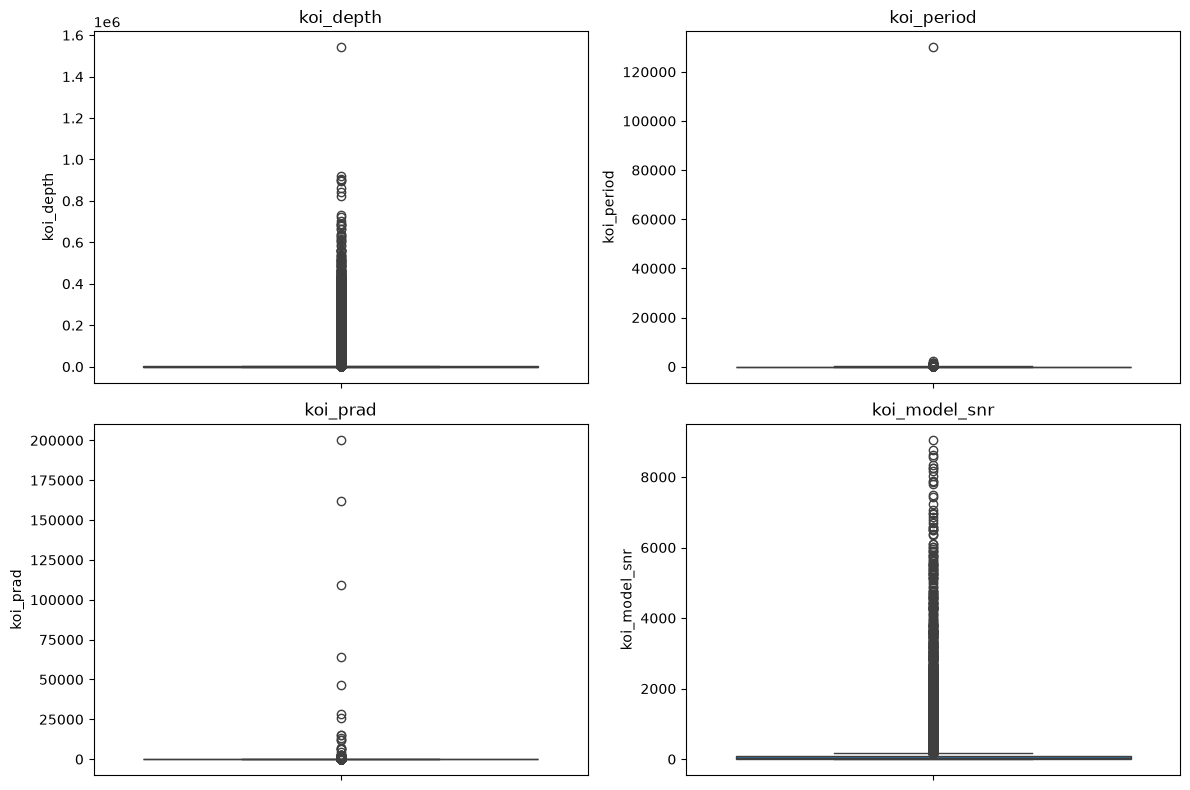

In [44]:
columns_to_plot = [
    'koi_depth',
    'koi_period',
    'koi_prad',
    'koi_model_snr'
]

plt.figure(figsize=(12, 8))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df_cleaned[column])
    plt.title(column)

plt.tight_layout()
plt.show()